# Minimum-VaR Portfolio Across the NIFTY 50, S&P 500 and Euro Stoxx 50

**Setup.** $10,000 is split across the three indices **once**, at the start of 2018, and held until the end of 2025. The weights are chosen to **minimise the portfolio's one-day Value at Risk** subject to a **target year-on-year expected return** that you set below.

**No look-ahead.** Everything used to pick the weights comes from the **training period (to the end of 2017)**:

* expected returns are the training-period average returns,
* the volatility of each index over 2018–2025 is the **multi-step GJR-GARCH-t forecast made on 29 Dec 2017**, and
* correlations are estimated from training-period standardised residuals.

The 2018–2025 data is used only to **evaluate** the portfolio. Its performance and risk are then compared with putting the whole $10,000 into a single index.

**Assumptions**

* Index returns are taken in **local currency** (INR, USD, EUR), as if currency risk were fully hedged, and treated as dollars. Dividends are excluded because these are price indices.
* No transaction costs. Fractional holdings are allowed.
* Buy and hold: after the initial split, the weights drift with prices (no rebalancing).

In [42]:
# ===================== USER PARAMETERS =====================
INITIAL_INVESTMENT = 10_000    # dollars
TARGET_RETURN      = 0.08    # target expected year-on-year return (0.14 = 14%)
VAR_LEVEL          = 0.99      # VaR confidence level used in the optimisation
ALLOW_SHORT        = False     # False: weights between 0 and 1
# ===========================================================

In [43]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from arch import arch_model
from scipy import stats
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.4f}".format)

SPLIT = "2018-01-01"
DATA = Path("data")
INDICES = {"NIFTY 50": "nifty50", "S&P 500": "sp500", "Euro Stoxx 50": "eurostoxx50"}
NAMES = list(INDICES)
COLORS = {"Min-VaR portfolio": "k", "NIFTY 50": "C1", "S&P 500": "C0", "Euro Stoxx 50": "C2"}

## 1. Data

Each index trades on its own holiday calendar. Prices are aligned on the union of trading days and carried forward over local holidays, so an index's return is zero on a day its market is closed. The common history starts on 17 Sep 2007, when the NIFTY 50 data begins.

In [44]:
def load_prices(slug):
    p = pd.read_csv(DATA / f"{slug}_daily.csv", index_col="Date", parse_dates=True)["Close"]
    return p.dropna()[lambda s: ~s.index.duplicated()]

own_prices = {name: load_prices(slug) for name, slug in INDICES.items()}
prices = pd.DataFrame(own_prices).ffill().dropna()
log_ret = 100 * np.log(prices).diff().dropna()          # % log returns on the common calendar
simple_ret = prices.pct_change().dropna()

train_prices, test_prices = prices[prices.index < SPLIT], prices[prices.index >= SPLIT]
print(f"Common calendar: {prices.index[0].date()} -> {prices.index[-1].date()}")
print(f"Training: {train_prices.index[0].date()} -> {train_prices.index[-1].date()} ({len(train_prices)} days)")
print(f"Test    : {test_prices.index[0].date()} -> {test_prices.index[-1].date()} ({len(test_prices)} days)")

Common calendar: 2007-09-17 -> 2025-12-31
Training: 2007-09-17 -> 2017-12-29 (2656 days)
Test    : 2018-01-02 -> 2025-12-31 (2073 days)


## 2. Inputs estimated on the training period only

### 2a. Univariate GJR-GARCH-t models

The same specification as Stage 1 is used: GJR-GARCH(1,1,1), constant mean, Student-t innovations, fitted on each index's own trading days up to the end of 2017.

In [45]:
models, fits, own_ret = {}, {}, {}
for name, p in own_prices.items():
    r = (100 * np.log(p).diff()).dropna()
    own_ret[name] = r
    models[name] = arch_model(r, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t")
    fits[name] = models[name].fit(last_obs=SPLIT, disp="off")

params = pd.DataFrame({n: f.params for n, f in fits.items()}).T
params[["mu", "omega", "alpha[1]", "gamma[1]", "beta[1]", "nu"]]

,mu,omega,alpha[1],gamma[1],beta[1],nu
NIFTY 50,0.0422,0.0149,0.0125,0.1170,0.9204,8.1012
S&P 500,0.0432,0.0104,0.0000,0.1462,0.9166,7.0020
Euro Stoxx 50,0.0154,0.0276,0.0000,0.1976,0.8920,7.6896


### 2b. Volatility forecast for the test period, made at the end of 2017

From the last training day, the model forecasts the daily variance for every day of the test period, $h = 1, \dots, H$. These forecasts start from the volatility level at the end of 2017 and revert towards the long-run level. Their average gives the **planning volatility**: the volatility the model expected for 2018–2025 using only information available on 29 Dec 2017.

,sigma at h=1 (% daily),planning sigma (% daily),planning sigma (% annual)
NIFTY 50,0.6459,1.2800,20.3190
S&P 500,0.4670,0.9853,15.6405
Euro Stoxx 50,0.8537,1.6940,26.8917


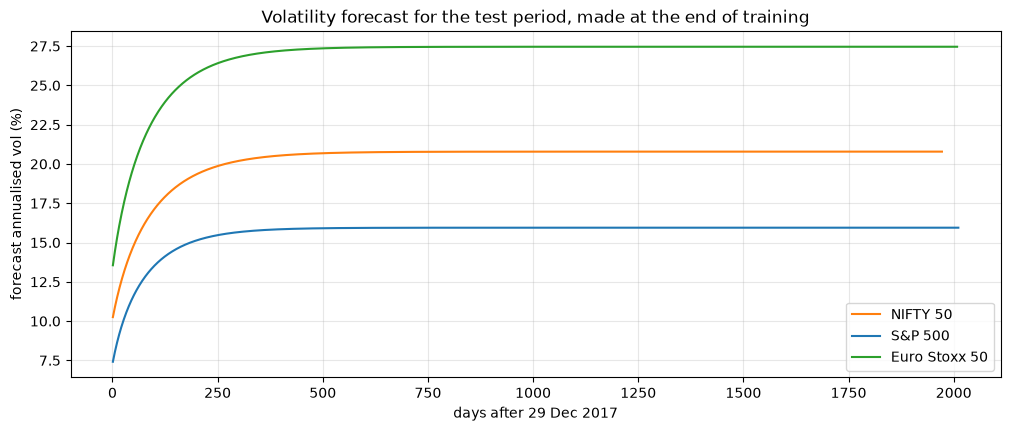

In [46]:
plan_sigma, plan_paths = {}, {}
for name, res in fits.items():
    r = own_ret[name]
    last_train = r.index[r.index < SPLIT][-1]
    H = int((r.index >= SPLIT).sum())
    fc = res.forecast(horizon=H, start=last_train, reindex=False)
    path = np.sqrt(fc.variance.iloc[0].values)          # daily sigma (%) for h = 1..H
    plan_paths[name] = path
    plan_sigma[name] = np.sqrt(np.mean(path ** 2))

fig, ax = plt.subplots()
for name, path in plan_paths.items():
    ax.plot(np.arange(1, len(path) + 1), path * np.sqrt(252), color=COLORS[name], label=name)
ax.set_xlabel("days after 29 Dec 2017"); ax.set_ylabel("forecast annualised vol (%)")
ax.set_title("Volatility forecast for the test period, made at the end of training"); ax.legend()

pd.DataFrame({
    "sigma at h=1 (% daily)": {n: p[0] for n, p in plan_paths.items()},
    "planning sigma (% daily)": plan_sigma,
    "planning sigma (% annual)": {n: s * np.sqrt(252) for n, s in plan_sigma.items()},
})

### 2c. Expected returns and correlations

* **Expected annual return** of each index: the training-period mean daily simple return × 252. The portfolio's expected return is then linear in the weights.
* **Correlation matrix**: correlation of the GARCH standardised residuals $\hat z_{i,t} = \hat\varepsilon_{i,t} / \hat\sigma_{i,t}$ over training days on which all three markets traded. This is the constant-conditional-correlation (CCC) assumption. A time-varying (DCC) model is planned for Stage 2.

Note that Indian trading closes before US trading opens, so same-day correlations understate how closely the markets are linked.

In [47]:
train_simple = simple_ret[simple_ret.index < SPLIT]
exp_daily = train_simple.mean()                     # expected daily simple return (fraction)
exp_annual = exp_daily * 252

std_resid = pd.DataFrame({
    n: (f.resid / f.conditional_volatility) for n, f in fits.items()
}).dropna()
std_resid = std_resid[std_resid.index >= train_prices.index[0]]
corr = std_resid.corr()

print("Expected annual return (training period):")
print((100 * exp_annual).round(2).astype(str) + "%")
print(f"\nCorrelation of standardised residuals ({len(std_resid)} common days):")
corr

Expected annual return (training period):
NIFTY 50         10.62%
S&P 500           7.67%
Euro Stoxx 50     1.15%
dtype: str

Correlation of standardised residuals (2395 common days):


,NIFTY 50,S&P 500,Euro Stoxx 50
NIFTY 50,1.0000,0.2636,0.3896
S&P 500,0.2636,1.0000,0.6300
Euro Stoxx 50,0.3896,0.6300,1.0000


## 3. Optimisation

For weights $w$ (summing to 1), the planning covariance matrix is $\Sigma = D R D$, with $D = \text{diag}(\sigma^{plan})$ and $R$ the correlation matrix. The portfolio's one-day VaR at confidence $c$ is

$$\text{VaR}(w) = -\left(w^\top \mu - q_{\nu}(c)\sqrt{w^\top \Sigma w}\right), \qquad q_{\nu}(c) = \text{standardised } t \text{ quantile},$$

where $\mu$ is the vector of expected daily returns and $\nu = \sum_i w_i \nu_i$ is a weight-averaged degrees-of-freedom parameter. The problem is

$$\min_w \ \text{VaR}(w) \quad \text{s.t.} \quad w^\top \mu^{annual} \ge \text{TARGET\_RETURN}, \quad \textstyle\sum_i w_i = 1, \quad 0 \le w_i \le 1.$$

In [48]:
mu_d = exp_daily[NAMES].values * 100                       # % daily
mu_a = exp_annual[NAMES].values
sig = np.array([plan_sigma[n] for n in NAMES])               # % daily
R = corr.loc[NAMES, NAMES].values
SIGMA = np.outer(sig, sig) * R
NU = np.array([fits[n].params["nu"] for n in NAMES])

def t_quantile(c, nu):
    # quantile of a unit-variance Student-t
    return stats.t.ppf(c, nu) * np.sqrt((nu - 2) / nu)

def portfolio_var(w, c=VAR_LEVEL, cov=SIGMA, mu=mu_d):
    nu = float(np.dot(w, NU))
    return -(w @ mu - t_quantile(c, nu) * np.sqrt(w @ cov @ w))

def optimise(target, c=VAR_LEVEL):
    bounds = None if ALLOW_SHORT else [(0, 1)] * len(NAMES)
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1},
            {"type": "ineq", "fun": lambda w: w @ mu_a - target}]
    best = None
    for w0 in [np.full(3, 1/3), np.eye(3)[np.argmax(mu_a)], np.array([0.4, 0.4, 0.2])]:
        res = minimize(portfolio_var, w0, args=(c,), bounds=bounds, constraints=cons,
                       method="SLSQP", options={"ftol": 1e-12, "maxiter": 500})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        raise ValueError(f"No feasible portfolio for target {target:.1%}")
    w = np.clip(best.x, 0 if not ALLOW_SHORT else -np.inf, None)
    return w / w.sum()

max_target = mu_a.max()
if TARGET_RETURN > max_target and not ALLOW_SHORT:
    raise ValueError(
        f"TARGET_RETURN = {TARGET_RETURN:.1%} cannot be reached without short selling: the highest "
        f"expected return of any index in the training period is {max_target:.2%} ({NAMES[np.argmax(mu_a)]}). "
        f"Choose a target of at most {max_target:.2%}.")

weights = pd.Series(optimise(TARGET_RETURN), index=NAMES)
w_minvar = optimise(-1.0)                        # no return constraint: the global minimum-VaR mix
minvar_return = w_minvar @ mu_a
if TARGET_RETURN <= minvar_return + 1e-6:
    print(f"Note: the return constraint is not binding. The lowest-VaR portfolio already has an expected "
          f"return of {minvar_return:.2%}, above the {TARGET_RETURN:.1%} target, so any target up to "
          f"{minvar_return:.2%} gives the same weights.\n")
plan = pd.DataFrame({
    "weight": weights,
    "initial allocation ($)": weights * INITIAL_INVESTMENT,
    "expected annual return": mu_a,
    "planning vol (annual %)": sig * np.sqrt(252),
})
print(f"Target expected return: {TARGET_RETURN:.1%}   achieved: {weights.values @ mu_a:.2%}")
print(f"Planned one-day {VAR_LEVEL:.0%} VaR: {portfolio_var(weights.values):.3f}%  "
      f"= ${portfolio_var(weights.values) / 100 * INITIAL_INVESTMENT:,.0f} on ${INITIAL_INVESTMENT:,}")
plan.style.format({"weight": "{:.1%}", "initial allocation ($)": "${:,.0f}",
                   "expected annual return": "{:.2%}", "planning vol (annual %)": "{:.2f}"})

Note: the return constraint is not binding. The lowest-VaR portfolio already has an expected return of 8.65%, above the 8.0% target, so any target up to 8.65% gives the same weights.

Target expected return: 8.0%   achieved: 8.65%
Planned one-day 99% VaR: 2.168%  = $217 on $10,000


,weight,initial allocation ($),expected annual return,planning vol (annual %)
NIFTY 50,33.5%,"$3,348",10.62%,20.32
S&P 500,66.5%,"$6,652",7.67%,15.64
Euro Stoxx 50,0.0%,$0,1.15%,26.89


### The VaR–return frontier (planning view)

Each point on the curve is the lowest planned VaR achievable for a given target return. The three single-index portfolios and an equal split are shown for comparison. The chosen portfolio is the star.

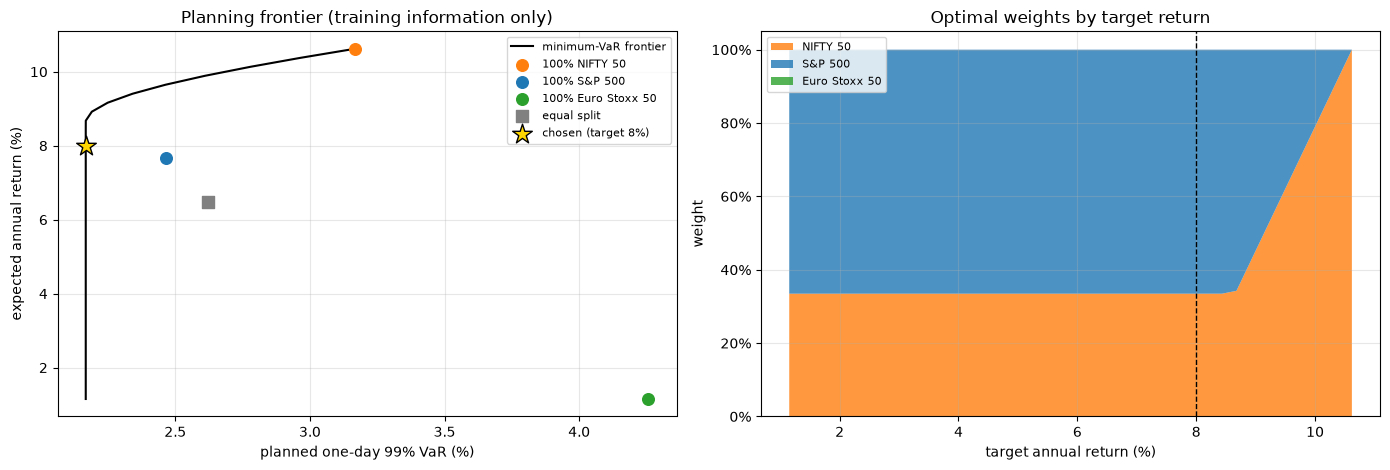

In [49]:
targets = np.linspace(max(mu_a.min(), 0.0), max_target, 40)
frontier = []
for t in targets:
    try:
        w = optimise(t)
        frontier.append({"target": t, "VaR": portfolio_var(w), **dict(zip(NAMES, w))})
    except ValueError:
        pass
frontier = pd.DataFrame(frontier)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(frontier["VaR"], 100 * frontier["target"], color="k", lw=1.5, label="minimum-VaR frontier")
for i, n in enumerate(NAMES):
    e = np.eye(3)[i]
    ax[0].scatter(portfolio_var(e), 100 * mu_a[i], s=70, color=COLORS[n], label=f"100% {n}", zorder=3)
eq = np.full(3, 1/3)
ax[0].scatter(portfolio_var(eq), 100 * eq @ mu_a, s=70, marker="s", color="0.5", label="equal split", zorder=3)
ax[0].scatter(portfolio_var(weights.values), 100 * TARGET_RETURN, s=220, marker="*", color="gold",
              edgecolor="k", label=f"chosen (target {TARGET_RETURN:.0%})", zorder=4)
ax[0].set_xlabel(f"planned one-day {VAR_LEVEL:.0%} VaR (%)"); ax[0].set_ylabel("expected annual return (%)")
ax[0].set_title("Planning frontier (training information only)"); ax[0].legend(fontsize=8)

ax[1].stackplot(100 * frontier["target"], *[frontier[n] for n in NAMES],
                labels=NAMES, colors=[COLORS[n] for n in NAMES], alpha=0.8)
ax[1].axvline(100 * TARGET_RETURN, color="k", ls="--", lw=1)
ax[1].set_xlabel("target annual return (%)"); ax[1].set_ylabel("weight")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax[1].set_title("Optimal weights by target return"); ax[1].legend(loc="upper left", fontsize=8)
plt.tight_layout()

## 4. Out-of-sample evaluation, 2018–2025

Four strategies, each starting with $10,000 on the first trading day of 2018 and held to the end of 2025:

| Strategy | Allocation |
|:--|:--|
| **Min-VaR portfolio** | the optimised weights above |
| **100% NIFTY 50** | whole sum in the NIFTY 50 |
| **100% S&P 500** | whole sum in the S&P 500 |
| **100% Euro Stoxx 50** | whole sum in the Euro Stoxx 50 |

**Daily VaR during the test.** The GARCH parameters stay fixed at their training values. Each day, the variance recursion is updated with the previous day's return to give a one-step-ahead $\hat\sigma_{i,t}$. The portfolio VaR then uses the **current drifted weights** $w_t$, the same correlation matrix and $\nu_t = \sum_i w_{i,t}\nu_i$. VaR is reported both as a percentage and in **dollars** (VaR % × the portfolio value the evening before).

In [50]:
# one-step-ahead sigma and mu for every test day (fixed training parameters), on each index's own calendar
step_sigma, step_mu = {}, {}
for name, res in fits.items():
    r = own_ret[name]
    last_train = r.index[r.index < SPLIT][-1]
    fc = res.forecast(horizon=1, start=last_train, reindex=False)
    step_sigma[name] = np.sqrt(fc.variance["h.1"]).shift(1)
    step_mu[name] = fc.mean["h.1"].shift(1)

test_idx = test_prices.index
sigma_t = pd.DataFrame(step_sigma).reindex(test_idx).ffill()
mu_t = pd.DataFrame(step_mu).reindex(test_idx).ffill()
# on a market's local holiday its return is zero by construction, so it contributes no risk that day
open_mask = pd.DataFrame({n: test_idx.isin(own_ret[n].index) for n in NAMES}, index=test_idx)
sigma_t = sigma_t.where(open_mask, 0.0)
mu_t = mu_t.where(open_mask, 0.0)

def simulate(w0, label):
    # buy-and-hold: fixed number of units bought on the first test day
    start_px = prices.loc[prices.index < SPLIT].iloc[-1]                 # last training close
    units = INITIAL_INVESTMENT * pd.Series(w0, index=NAMES) / start_px
    holdings = test_prices[NAMES] * units                                 # $ in each index, end of day
    value = holdings.sum(axis=1)
    prev_value = value.shift(1).fillna(INITIAL_INVESTMENT)
    prev_hold = holdings.shift(1).fillna(INITIAL_INVESTMENT * pd.Series(w0, index=NAMES))
    w_t = prev_hold.div(prev_value, axis=0)                               # weights at start of each day

    var_pct = np.empty(len(test_idx))
    for k, d in enumerate(test_idx):
        w = w_t.loc[d].values
        D = sigma_t.loc[d].values
        cov = np.outer(D, D) * R
        nu = float(w @ NU)
        var_pct[k] = -(w @ mu_t.loc[d].values - t_quantile(VAR_LEVEL, nu) * np.sqrt(max(w @ cov @ w, 0)))
    out = pd.DataFrame({
        "value": value,
        "ret_pct": 100 * (value / prev_value - 1),
        "log_ret_pct": 100 * np.log(value / prev_value),
        "VaR_pct": var_pct,
    }, index=test_idx)
    out["VaR_usd"] = out["VaR_pct"] / 100 * prev_value
    out["loss_usd"] = prev_value - value
    out.attrs["label"] = label
    return out

strategies = {"Min-VaR portfolio": weights.values}
strategies.update({n: np.eye(3)[i] for i, n in enumerate(NAMES)})
results = {label: simulate(w, label) for label, w in strategies.items()}

### Growth of $10,000

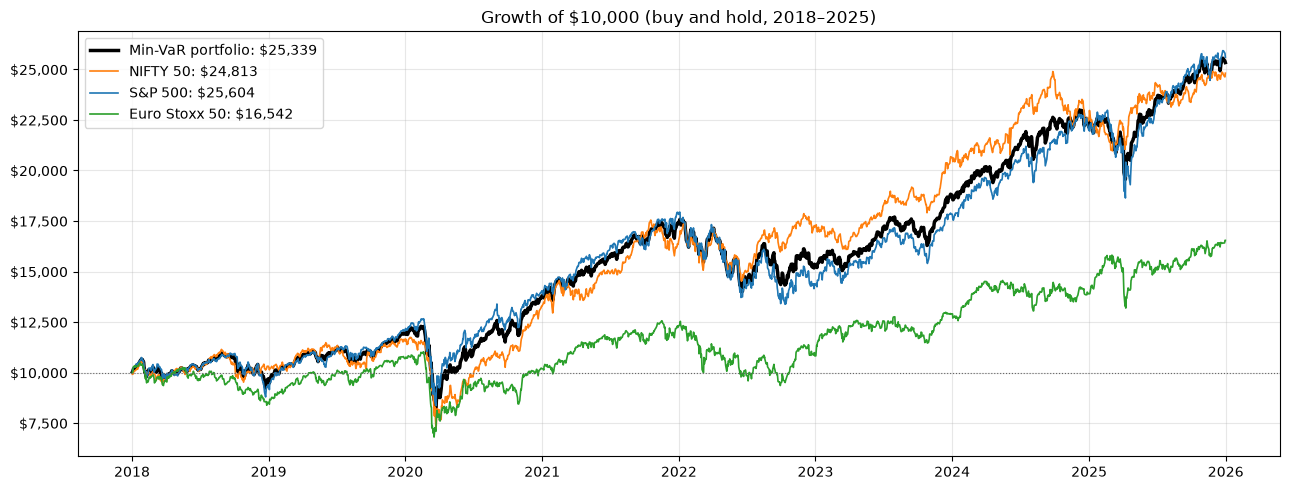

In [51]:
fig, ax = plt.subplots(figsize=(13, 5))
for label, df in results.items():
    lw = 2.5 if label == "Min-VaR portfolio" else 1.2
    ax.plot(df.index, df["value"], color=COLORS[label], lw=lw,
            label=f"{label}: ${df['value'].iloc[-1]:,.0f}")
ax.axhline(INITIAL_INVESTMENT, color="0.4", lw=0.8, ls=":")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_title(f"Growth of ${INITIAL_INVESTMENT:,} (buy and hold, 2018–2025)"); ax.legend(loc="upper left")
plt.tight_layout()

### Daily one-day VaR in dollars

This is how much each strategy could lose on a bad day (1 day in 100 at 99%), based on its value and the GARCH risk forecast that day.

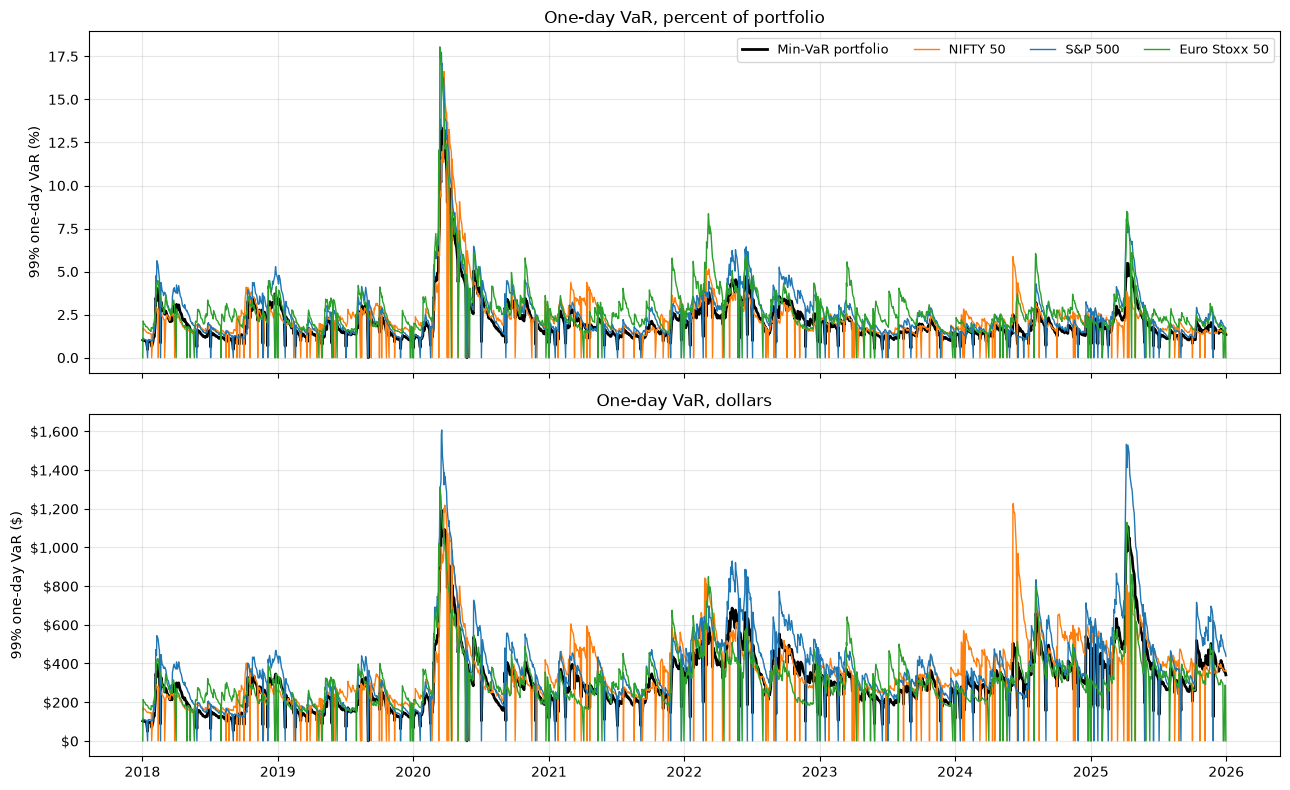

In [52]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for label, df in results.items():
    lw = 2 if label == "Min-VaR portfolio" else 1
    ax[0].plot(df.index, df["VaR_pct"], color=COLORS[label], lw=lw, label=label)
    ax[1].plot(df.index, df["VaR_usd"], color=COLORS[label], lw=lw, label=label)
ax[0].set_ylabel(f"{VAR_LEVEL:.0%} one-day VaR (%)"); ax[0].set_title("One-day VaR, percent of portfolio")
ax[1].set_ylabel(f"{VAR_LEVEL:.0%} one-day VaR ($)"); ax[1].set_title("One-day VaR, dollars")
ax[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax[0].legend(ncol=4, fontsize=9)
plt.tight_layout()

## 5. Risk and return comparison

**Return measures:** final value, total return, annualised return (CAGR), best and worst calendar year.

**Risk measures:**

* **Forecast VaR:** the average and peak of the daily 99% GARCH VaR, in % and in $.
* **Realised VaR (historical 1%):** the actual 1st-percentile daily return over the test period. This is what the forecast VaR is trying to predict.
* **VaR breaches:** days on which the actual loss exceeded that day's forecast VaR, with the Kupiec test p-value (p < 0.05 means the VaR is miscalibrated).
* **Annualised volatility, maximum drawdown and worst single day.**

**Risk-adjusted:** Sharpe ratio (zero risk-free rate) and CAGR ÷ average VaR.

In the table, green marks the best strategy on each row and red the worst.

In [53]:
def kupiec_p(hits, p):
    n, x = len(hits), int(hits.sum())
    if x == 0:
        lr = -2 * n * np.log(1 - p)
    else:
        pi = x / n
        lr = -2 * ((n - x) * np.log(1 - p) + x * np.log(p) - (n - x) * np.log(1 - pi) - x * np.log(pi))
    return 1 - stats.chi2.cdf(lr, 1)

def metrics(df):
    v = df["value"]
    years = len(df) / 252
    cagr = (v.iloc[-1] / INITIAL_INVESTMENT) ** (1 / years) - 1
    r = df["ret_pct"] / 100
    dd = v / v.cummax() - 1
    yearly = v.groupby(v.index.year).last()
    yearly = yearly / pd.concat([pd.Series([INITIAL_INVESTMENT]), yearly.iloc[:-1]]).values - 1
    hits = df["log_ret_pct"] < -df["VaR_pct"]
    return {
        "Final value ($)": v.iloc[-1],
        "Total return": v.iloc[-1] / INITIAL_INVESTMENT - 1,
        "Annualised return (CAGR)": cagr,
        "Best year": yearly.max(),
        "Worst year": yearly.min(),
        "Avg forecast 99% VaR (%)": df["VaR_pct"].mean(),
        "Avg forecast 99% VaR ($)": df["VaR_usd"].mean(),
        "Peak forecast 99% VaR ($)": df["VaR_usd"].max(),
        "Realised 1% daily return (%)": -np.percentile(df["ret_pct"], 1),
        "VaR breaches (days)": int(hits.sum()),
        "VaR breach rate": hits.mean(),
        "Kupiec p": kupiec_p(hits, 1 - VAR_LEVEL),
        "Annualised volatility": r.std() * np.sqrt(252),
        "Max drawdown": dd.min(),
        "Worst day ($)": df["loss_usd"].max(),
        "Sharpe ratio (rf = 0)": r.mean() / r.std() * np.sqrt(252),
        "CAGR / avg VaR": 100 * cagr / df["VaR_pct"].mean(),
    }

comparison = pd.DataFrame({label: metrics(df) for label, df in results.items()})

higher_better = {"Final value ($)", "Total return", "Annualised return (CAGR)", "Best year", "Worst year",
                 "Max drawdown", "Sharpe ratio (rf = 0)", "CAGR / avg VaR", "Kupiec p"}
lower_better = {"Avg forecast 99% VaR (%)", "Avg forecast 99% VaR ($)", "Peak forecast 99% VaR ($)",
                "Realised 1% daily return (%)", "Annualised volatility", "Worst day ($)"}

def highlight(row):
    if row.name in higher_better:
        best, worst = row.max(), row.min()
    elif row.name in lower_better:
        best, worst = row.min(), row.max()
    else:
        return [""] * len(row)
    return ["background-color: #d4edda; font-weight: bold" if v == best else
            "background-color: #f8d7da" if v == worst else "" for v in row]

fmt = {
    "Final value ($)": "${:,.0f}", "Avg forecast 99% VaR ($)": "${:,.0f}", "Peak forecast 99% VaR ($)": "${:,.0f}",
    "Worst day ($)": "${:,.0f}",
    "Total return": "{:.1%}", "Annualised return (CAGR)": "{:.2%}", "Best year": "{:.1%}", "Worst year": "{:.1%}",
    "VaR breach rate": "{:.2%}", "Annualised volatility": "{:.1%}", "Max drawdown": "{:.1%}",
    "Avg forecast 99% VaR (%)": "{:.2f}%", "Realised 1% daily return (%)": "{:.2f}%",
    "VaR breaches (days)": "{:.0f}", "Kupiec p": "{:.3f}", "Sharpe ratio (rf = 0)": "{:.2f}", "CAGR / avg VaR": "{:.2f}",
}

def show(table):
    sty = table.style.apply(highlight, axis=1)
    for row, f in fmt.items():
        if row in table.index:
            sty = sty.format(f, subset=pd.IndexSlice[row, :])
    return sty

print(f"Min-VaR weights: " + ", ".join(f"{n} {w:.1%}" for n, w in weights.items())
      + f"   (target {TARGET_RETURN:.0%} p.a.)")
show(comparison)

Min-VaR weights: NIFTY 50 33.5%, S&P 500 66.5%, Euro Stoxx 50 0.0%   (target 8% p.a.)


,Min-VaR portfolio,NIFTY 50,S&P 500,Euro Stoxx 50
Final value ($),"$25,339","$24,813","$25,604","$16,542"
Total return,153.4%,148.1%,156.0%,65.4%
Annualised return (CAGR),11.97%,11.68%,12.11%,6.31%
Best year,26.0%,24.1%,28.9%,25.5%
Worst year,-11.9%,3.2%,-19.4%,-14.8%
Avg forecast 99% VaR (%),2.08%,2.34%,2.58%,2.78%
Avg forecast 99% VaR ($),$310,$352,$383,$311
Peak forecast 99% VaR ($),"$1,191","$1,227","$1,606","$1,311"
Realised 1% daily return (%),2.56%,2.67%,3.41%,3.64%
VaR breaches (days),39,25,33,28


### Risk vs return at a glance

Left: annualised return against average forecast VaR. Right: annualised return against maximum drawdown. Up and to the left is better in both.

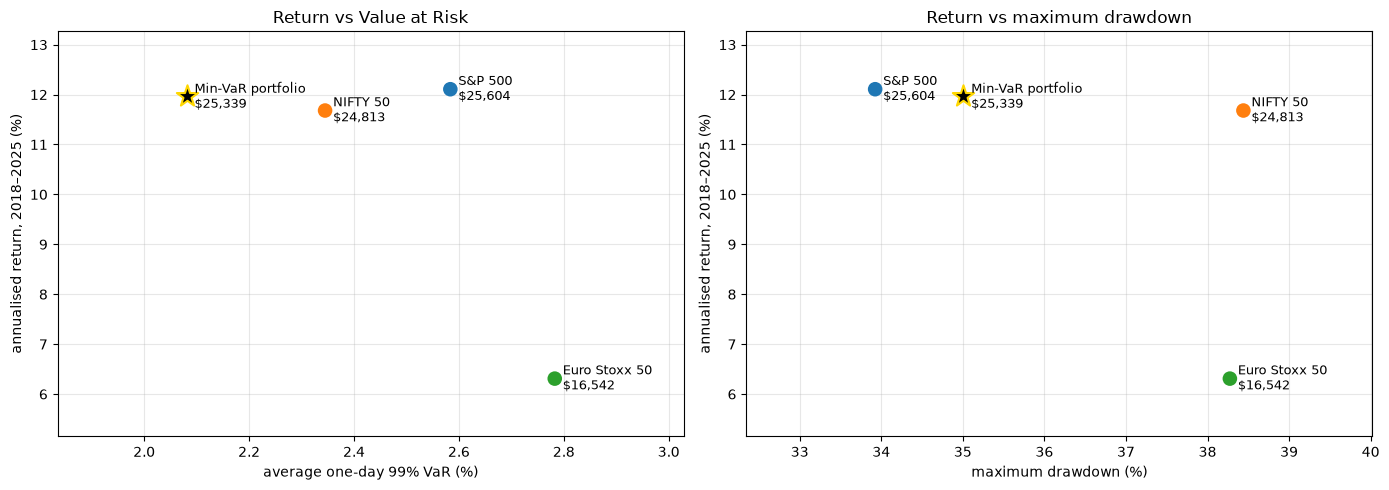

In [54]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for label in results:
    c = comparison[label]
    big = label == "Min-VaR portfolio"
    kw = dict(s=260 if big else 110, color=COLORS[label], marker="*" if big else "o",
              edgecolor="gold" if big else "none", linewidth=1.5, zorder=3)
    ax[0].scatter(c["Avg forecast 99% VaR (%)"], 100 * c["Annualised return (CAGR)"], **kw)
    ax[1].scatter(-100 * c["Max drawdown"], 100 * c["Annualised return (CAGR)"], **kw)
    for a, x in [(ax[0], c["Avg forecast 99% VaR (%)"]), (ax[1], -100 * c["Max drawdown"])]:
        a.annotate(f"  {label}\n  ${c['Final value ($)']:,.0f}", (x, 100 * c["Annualised return (CAGR)"]),
                   fontsize=9, va="center")
ax[0].set_xlabel("average one-day 99% VaR (%)"); ax[0].set_ylabel("annualised return, 2018–2025 (%)")
ax[0].set_title("Return vs Value at Risk")
ax[1].set_xlabel("maximum drawdown (%)"); ax[1].set_ylabel("annualised return, 2018–2025 (%)")
ax[1].set_title("Return vs maximum drawdown")
for a in ax:
    a.margins(x=0.35, y=0.2)
plt.tight_layout()

### Year-by-year return and risk

Calendar-year return of each strategy, and its average dollar VaR during that year.

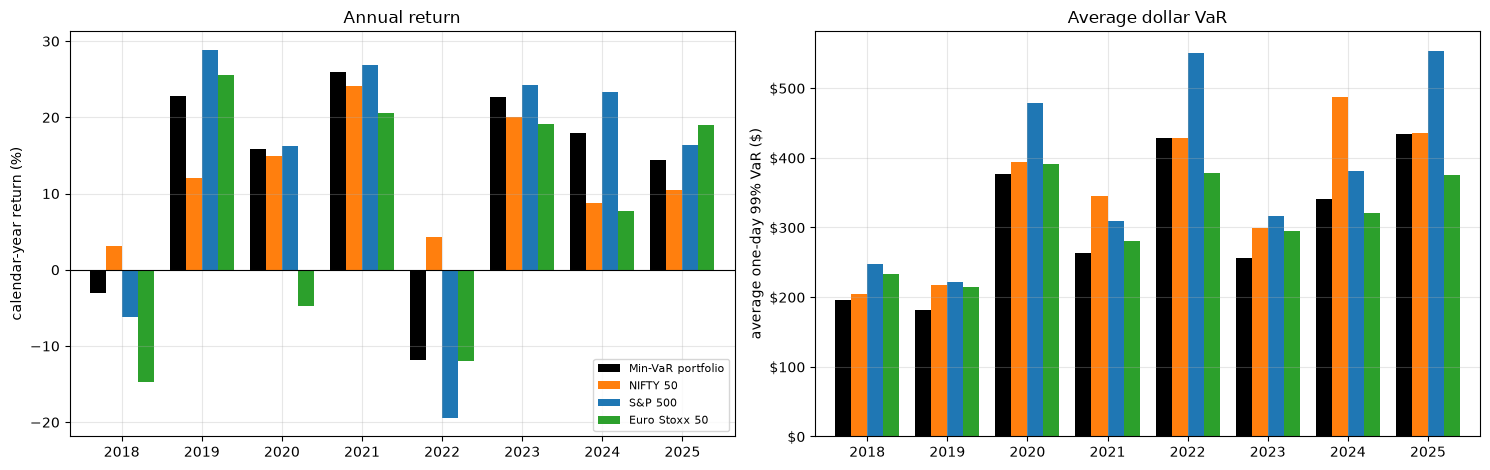

In [55]:
def yearly_stats(df):
    v = df["value"]
    ye = v.groupby(v.index.year).last()
    start = pd.concat([pd.Series([INITIAL_INVESTMENT]), ye.iloc[:-1]]).values
    return pd.DataFrame({"return": ye / start - 1,
                         "avg VaR ($)": df["VaR_usd"].groupby(df.index.year).mean(),
                         "year-end value ($)": ye})

yearly = pd.concat({label: yearly_stats(df) for label, df in results.items()}, axis=1)
yr_ret = yearly.xs("return", axis=1, level=1)
yr_var = yearly.xs("avg VaR ($)", axis=1, level=1)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
yr_ret.mul(100).plot(kind="bar", ax=ax[0], color=[COLORS[c] for c in yr_ret.columns], width=0.8)
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_ylabel("calendar-year return (%)"); ax[0].set_xlabel("")
ax[0].set_title("Annual return"); ax[0].tick_params(axis="x", rotation=0); ax[0].legend(fontsize=8)
yr_var.plot(kind="bar", ax=ax[1], color=[COLORS[c] for c in yr_var.columns], width=0.8, legend=False)
ax[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax[1].set_ylabel("average one-day 99% VaR ($)"); ax[1].set_xlabel("")
ax[1].set_title("Average dollar VaR"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()

(yearly.style
   .format("{:.1%}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "return"]])
   .format("${:,.0f}", subset=pd.IndexSlice[:, pd.IndexSlice[:, ["avg VaR ($)", "year-end value ($)"]]])
   .background_gradient(cmap="RdYlGn", vmin=-0.3, vmax=0.3, subset=pd.IndexSlice[:, pd.IndexSlice[:, "return"]]))

### Is the portfolio VaR well calibrated?

The single-index VaR series reproduce the Stage 1 backtests exactly. The portfolio's VaR combines them under two simplifications: a constant correlation matrix, and a Student-t tail whose $\nu$ is the weighted average of the three indices' $\nu$. The cell below checks each part separately:

* **Volatility:** if the portfolio volatility forecast is right, the standardised portfolio return $r_{p,t} / \hat\sigma_{p,t}$ should have a standard deviation near 1.
* **Tail:** its empirical 1st percentile should match the t quantile the VaR uses.

In [56]:
w_hist = results["Min-VaR portfolio"]
units = INITIAL_INVESTMENT * weights / prices.loc[prices.index < SPLIT].iloc[-1]
hold = test_prices[NAMES] * units
w_start = hold.shift(1).fillna(INITIAL_INVESTMENT * weights).pipe(lambda h: h.div(h.sum(axis=1), axis=0))
port_sigma = pd.Series([np.sqrt((sigma_t.loc[d].values * w_start.loc[d].values) @ R
                                @ (sigma_t.loc[d].values * w_start.loc[d].values)) for d in test_idx], index=test_idx)
z_port = (w_hist["log_ret_pct"] - (w_start * mu_t).sum(axis=1)) / port_sigma
q_model = -t_quantile(VAR_LEVEL, float(weights.values @ NU))
q_emp = z_port.quantile(1 - VAR_LEVEL)
calib = pd.Series({
    "std of standardised portfolio return (target 1.00)": z_port.std(),
    f"model {1 - VAR_LEVEL:.0%} quantile (t, weighted ν)": q_model,
    f"empirical {1 - VAR_LEVEL:.0%} quantile": q_emp,
    "VaR understated by": q_emp / q_model - 1,
})
print(calib.to_string(float_format=lambda x: f"{x:.3f}"))
print(f"\nBreaches by year: {(w_hist['log_ret_pct'] < -w_hist['VaR_pct']).groupby(test_idx.year).sum().to_dict()}")

std of standardised portfolio return (target 1.00)    0.972
model 1% quantile (t, weighted ν)                    -2.524
empirical 1% quantile                                -2.869
VaR understated by                                    0.137

Breaches by year: {2018: 5, 2019: 4, 2020: 8, 2021: 6, 2022: 4, 2023: 2, 2024: 6, 2025: 4}


## 6. Sensitivity to the target return

The same exercise repeated for a range of targets, from the global minimum-VaR portfolio up to the highest achievable expected return (100% in the index with the highest training-period return). Targets below the minimum-VaR portfolio's own expected return give the same weights, so they are not listed separately. It shows what each extra point of target return cost in VaR **as planned**, and what it delivered **out of sample**.

In [57]:
sweep_targets = sorted(set(np.round(np.r_[minvar_return, np.arange(np.ceil(minvar_return * 200) / 200, max_target, 0.005),
                                          max_target, TARGET_RETURN], 4)))
rows = []
for t in sweep_targets:
    try:
        w = optimise(t)
    except ValueError:
        continue
    df = simulate(w, f"{t:.0%}")
    m = metrics(df)
    rows.append({
        "target": t, **{f"w {n}": wi for n, wi in zip(NAMES, w)},
        "planned VaR (%)": portfolio_var(w),
        "test CAGR": m["Annualised return (CAGR)"],
        "test avg VaR ($)": m["Avg forecast 99% VaR ($)"],
        "test max drawdown": m["Max drawdown"],
        "final value ($)": m["Final value ($)"],
        "breach rate": m["VaR breach rate"],
    })
sweep = pd.DataFrame(rows).set_index("target")
sweep.index = [f"{t:.2%}" + ("  (min-VaR)" if np.isclose(t, round(minvar_return, 4)) else "")
               + ("  ← chosen" if np.isclose(t, TARGET_RETURN) else "") for t in sweep.index]

(sweep.style
   .format({**{f"w {n}": "{:.1%}" for n in NAMES}, "planned VaR (%)": "{:.3f}", "test CAGR": "{:.2%}",
            "test avg VaR ($)": "${:,.0f}", "test max drawdown": "{:.1%}", "final value ($)": "${:,.0f}",
            "breach rate": "{:.2%}"})
   .background_gradient(cmap="Greens", subset=["test CAGR", "final value ($)"])
   .background_gradient(cmap="Reds", subset=["planned VaR (%)", "test avg VaR ($)"]))

,w NIFTY 50,w S&P 500,w Euro Stoxx 50,planned VaR (%),test CAGR,test avg VaR ($),test max drawdown,final value ($),breach rate
8.00% ← chosen,33.5%,66.5%,0.0%,2.168,11.97%,$310,-35.0%,"$25,339",1.88%
8.65% (min-VaR),33.5%,66.5%,0.0%,2.168,11.97%,$310,-35.0%,"$25,339",1.88%
9.00%,45.2%,54.8%,0.0%,2.206,11.92%,$298,-35.4%,"$25,246",1.54%
9.50%,62.1%,37.9%,0.0%,2.386,11.84%,$296,-36.2%,"$25,113",1.30%
10.00%,79.0%,21.0%,0.0%,2.684,11.77%,$311,-37.2%,"$24,979",1.25%
10.50%,96.0%,4.0%,0.0%,3.066,11.70%,$342,-38.2%,"$24,845",1.21%


## 7. Summary

The cell below prints a plain-language summary for the chosen target. Change `TARGET_RETURN` at the top and re-run all cells to see a different portfolio.

In [58]:
c = comparison
pv = c["Min-VaR portfolio"]
singles = [n for n in NAMES]
print(f"Target expected return: {TARGET_RETURN:.1%} per year")
print("Weights: " + ", ".join(f"{n} {w:.1%} (${w * INITIAL_INVESTMENT:,.0f})" for n, w in weights.items()))
print()
print(f"{'':22s}{'final value':>13s}{'CAGR':>9s}{'avg VaR $':>11s}{'avg VaR %':>11s}{'max DD':>9s}{'Sharpe':>8s}")
for label in c.columns:
    x = c[label]
    print(f"{label:22s}{x['Final value ($)']:>13,.0f}{x['Annualised return (CAGR)']:>9.2%}"
          f"{x['Avg forecast 99% VaR ($)']:>11,.0f}{x['Avg forecast 99% VaR (%)']:>10.2f}%"
          f"{x['Max drawdown']:>9.1%}{x['Sharpe ratio (rf = 0)']:>8.2f}")
print()
lowest_single = min(singles, key=lambda n: c.loc["Avg forecast 99% VaR (%)", n])
print(f"Average VaR of the portfolio vs the lowest-risk single index ({lowest_single}): "
      f"{pv['Avg forecast 99% VaR (%)']:.2f}% vs {c.loc['Avg forecast 99% VaR (%)', lowest_single]:.2f}%")
print(f"Realised CAGR vs target: {pv['Annualised return (CAGR)']:.2%} vs {TARGET_RETURN:.1%}")
print(f"VaR breaches: {pv['VaR breaches (days)']:.0f} days ({pv['VaR breach rate']:.2%}, "
      f"expected {1 - VAR_LEVEL:.0%}), Kupiec p = {pv['Kupiec p']:.3f}")

Target expected return: 8.0% per year
Weights: NIFTY 50 33.5% ($3,348), S&P 500 66.5% ($6,652), Euro Stoxx 50 0.0% ($0)

                        final value     CAGR  avg VaR $  avg VaR %   max DD  Sharpe
Min-VaR portfolio            25,339   11.97%        310      2.08%   -35.0%    0.82
NIFTY 50                     24,813   11.68%        352      2.34%   -38.4%    0.75
S&P 500                      25,604   12.11%        383      2.58%   -33.9%    0.69
Euro Stoxx 50                16,542    6.31%        311      2.78%   -38.3%    0.42

Average VaR of the portfolio vs the lowest-risk single index (NIFTY 50): 2.08% vs 2.34%
Realised CAGR vs target: 11.97% vs 8.0%
VaR breaches: 39 days (1.88%, expected 1%), Kupiec p = 0.000


### Findings (default settings: 8% target, 99% VaR)

**The portfolio.** The optimiser puts **33.5% ($3,348) in the NIFTY 50 and 66.5% ($6,652) in the S&P 500**, and nothing in the Euro Stoxx 50. The 8% target is **not binding**: the lowest-VaR mix already has an expected return of 8.65%, so any target up to 8.65% gives the same weights. The Euro Stoxx 50 is excluded because, on the training data, it had both the highest planning volatility (26.9% a year) and the lowest expected return (1.2%). Its correlation of 0.63 with the S&P 500 also means it adds little diversification.

**Returns.** $10,000 grew to **$25,339** (12.0% a year), above the 8% target. This is almost the same as 100% S&P 500 ($25,604, 12.1%) and 100% NIFTY 50 ($24,813, 11.7%), and far ahead of 100% Euro Stoxx 50 ($16,542, 6.3%).

**Risk.** The portfolio was the lowest-risk option on almost every measure:

| Measure | Min-VaR | NIFTY 50 | S&P 500 | Euro Stoxx 50 |
|:--|--:|--:|--:|--:|
| Average forecast 99% VaR | **2.08%** | 2.34% | 2.58% | 2.78% |
| Realised 1% worst daily return | **2.56%** | 2.67% | 3.41% | 3.64% |
| Annualised volatility | **15.2%** | 16.6% | 19.3% | 18.6% |
| Maximum drawdown | 35.0% | 38.4% | **33.9%** | 38.3% |
| Sharpe ratio | **0.82** | 0.75 | 0.69 | 0.42 |

It matched the best single index on return with about 20% less forecast VaR than the S&P 500, and had the best return per unit of risk. Its average dollar VaR ($310) is about the same as the Euro Stoxx 50's ($311), but only because the Euro Stoxx position shrank in value. The exception is maximum drawdown, where the S&P 500 alone was slightly better, because the NIFTY sleeve fell further in the March 2020 crash.

**Calibration caveat.** The portfolio's VaR was breached on 39 days (1.88%) against about 21 expected, and the Kupiec test rejects it. The volatility forecast itself is accurate: the standardised returns have a standard deviation of about 0.97. The problem is the tail. The worst 1% of standardised portfolio returns reached −2.87, against −2.52 assumed by the weighted-ν t distribution, so the 99% VaR is understated by about 14%. Two things cause this. First, the portfolio is two-thirds S&P 500, whose own 99% VaR already fails its backtest (Stage 1). Second, markets fall together more in a crash than their average correlation implies. Scaled up by 14%, the portfolio's average VaR would be about 2.37%. That is level with the NIFTY 50 alone (2.34%, which is well calibrated) and still below the S&P 500 and Euro Stoxx 50. On the realised 1% loss, which needs no model, the portfolio is still the safest of the four. Stage 2 (DCC-GARCH, a time-varying correlation model) and a fatter-tailed or filtered-historical-simulation quantile would address this.

**Raising the target.** Asking for more than 8.65% shifts weight from the S&P 500 to the NIFTY 50 (79% NIFTY at a 10% target). This raises planned VaR but did not raise realised returns over 2018–2025, because the S&P 500 did better than its training-period average.